<a href="https://colab.research.google.com/github/MarkowitzMx/Programacion-para-analitica-descriptiva-y-predictiva-2026/blob/main/Arbol_Decision_Regresion_California_Housing_274690.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: Árbol de Decisión para Regresión

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**

**Nombre: Cristóbal Lemus Rendón**

**Matrícula: 274690**

**Ficha técnica**

| | |
|---|---|
| **Modalidad** | Individual |
| **Entorno** | Google Colab |
| **Dataset** | California Housing (scikit-learn, regresión) |
| **Modelo** | Árbol de Decisión (`DecisionTreeRegressor`) |
| **Variable objetivo** | `MedHouseVal` (valor mediano de la vivienda, en unidades de 100 000 dólares) |
| **Métricas** | RMSE y R² |

**Objetivo**

Analizar el comportamiento de un árbol de decisión en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del sobreajuste, la profundidad del árbol (análisis sesgo–varianza) y la poda por complejidad de costo (`ccp_alpha`).

**Dataset**

California Housing contiene 20 640 distritos censales de California (censo de 1990) con 8 variables predictoras numéricas y sin valores faltantes. La variable objetivo es `MedHouseVal`.

**Instrucciones generales**

- Ejecuta el notebook de principio a fin (`Entorno de ejecución > Reiniciar y ejecutar todo` en Colab) y verifica que no queden errores.
- Cada actividad tiene una parte de código (comentada línea por línea) y una pregunta de interpretación. Las celdas marcadas como **valores reales** imprimen las cifras obtenidas al ejecutar, para que las respuestas estén respaldadas por resultados y no por suposiciones.
- La Actividad 5 (poda) evalúa cientos de árboles, por lo que puede tardar algunos minutos en Colab. Esta actividad tarda mas de 60 minutos en correr dado que se solicita un muestreo de **[::5]**.

**Entrega**

Sube a Moodle un archivo `.txt` con el enlace a tu notebook de Colab o GitHub (con permisos de lectura habilitados).

## Importación de bibliotecas

In [1]:
import pandas as pd  # pandas: organiza los datos en tablas (DataFrame)
import numpy as np  # NumPy: operaciones numéricas y arreglos
import matplotlib.pyplot as plt  # Matplotlib: crea las gráficas
import seaborn as sns  # Seaborn: visualización estadística sobre Matplotlib
from sklearn.datasets import fetch_california_housing  # función que carga el dataset California Housing
from sklearn.model_selection import train_test_split, cross_val_score  # partición entrenamiento/prueba y validación cruzada
from sklearn.tree import DecisionTreeRegressor  # modelo de árbol de decisión para regresión
from sklearn.metrics import mean_squared_error, r2_score  # métricas: MSE (para obtener RMSE) y R²

sns.set_theme(style="whitegrid")  # estilo visual uniforme para todas las gráficas
pd.set_option("display.precision", 4)  # muestra las tablas con 4 decimales
RANDOM_STATE = 42  # semilla fija para que los resultados sean reproducibles


def evaluar(modelo, X_tr, y_tr, X_te, y_te):  # función auxiliar que calcula RMSE y R² en entrenamiento y prueba
    p_tr = modelo.predict(X_tr)  # predicciones sobre el conjunto de entrenamiento
    p_te = modelo.predict(X_te)  # predicciones sobre el conjunto de prueba
    rmse_tr = np.sqrt(mean_squared_error(y_tr, p_tr))  # RMSE de entrenamiento: raíz del error cuadrático medio
    rmse_te = np.sqrt(mean_squared_error(y_te, p_te))  # RMSE de prueba
    r2_tr = r2_score(y_tr, p_tr)  # R² de entrenamiento: proporción de varianza explicada
    r2_te = r2_score(y_te, p_te)  # R² de prueba
    return rmse_tr, rmse_te, r2_tr, r2_te  # devuelve las cuatro métricas en una tupla

---
## Actividad 1 — Carga y exploración de datos

**1.1.** Carga el dataset en un DataFrame, identifica la variable objetivo (`MedHouseVal`), analiza la estructura (`info`, `describe`) y visualiza la distribución de la variable objetivo.

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.9841,1.0238,322.0,2.5556,37.88,-122.23,4.526
1,8.3014,21.0,6.2381,0.9719,2401.0,2.1098,37.86,-122.22,3.585
2,7.2574,52.0,8.2881,1.0734,496.0,2.8023,37.85,-122.24,3.521
3,5.6431,52.0,5.8174,1.0731,558.0,2.5479,37.85,-122.25,3.413
4,3.8462,52.0,6.2819,1.0811,565.0,2.1815,37.85,-122.25,3.422


Dimensiones (filas, columnas): (20640, 9)
Variable objetivo: MedHouseVal
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
HouseAge,20640.0,28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
AveRooms,20640.0,5.4290,2.4742,0.8462,4.4407,5.2291,6.0524,141.9091
AveBedrms,20640.0,1.0967,0.4739,0.3333,1.0061,1.0488,1.0995,34.0667
Population,20640.0,1425.4767,1132.4621,3.0000,787.0000,1166.0000,1725.0000,35682.0000
AveOccup,20640.0,3.0707,10.3860,0.6923,2.4297,2.8181,3.2823,1243.3333
Latitude,20640.0,35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
Longitude,20640.0,-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
MedHouseVal,20640.0,2.0686,1.1540,0.1500,1.1960,1.7970,2.6472,5.0000


Valores faltantes por columna:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


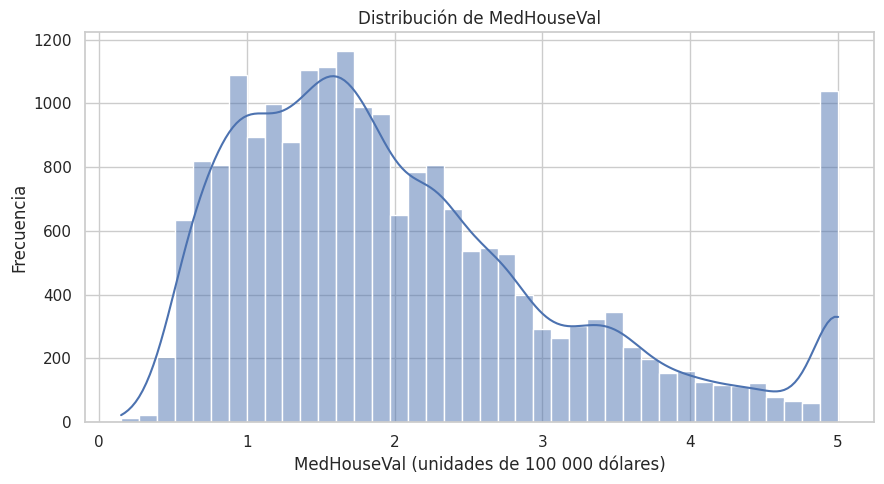

In [2]:
housing = fetch_california_housing(as_frame=True)  # descarga/carga California Housing con formato pandas
df = housing.frame.copy()  # copia el DataFrame (predictoras + objetivo) para no modificar el original
display(df.head())  # muestra las primeras cinco observaciones
print("Dimensiones (filas, columnas):", df.shape)  # imprime la cantidad de filas y columnas
print("Variable objetivo: MedHouseVal")  # indica cuál es la variable que se desea predecir
df.info()  # muestra tipos de dato y cantidad de valores no nulos por columna
display(df.describe().T)  # estadísticas descriptivas (media, desviación, cuartiles) transpuestas
print("Valores faltantes por columna:")  # encabezado del conteo de faltantes
display(df.isna().sum())  # cuenta los valores faltantes en cada columna
plt.figure(figsize=(9, 5))  # crea una figura de 9 x 5 pulgadas
sns.histplot(df["MedHouseVal"], bins=40, kde=True)  # histograma de 40 barras con curva de densidad
plt.title("Distribución de MedHouseVal")  # título de la gráfica
plt.xlabel("MedHouseVal (unidades de 100 000 dólares)")  # etiqueta del eje X
plt.ylabel("Frecuencia")  # etiqueta del eje Y
plt.tight_layout()  # ajusta los márgenes para que no se corten las etiquetas
plt.show()  # muestra la gráfica

**Valores reales de la exploración** (se calculan al ejecutar).

In [3]:
maximo = df["MedHouseVal"].max()  # valor máximo observado de la variable objetivo
pct_tope = (df["MedHouseVal"] == maximo).mean() * 100  # porcentaje de distritos que están exactamente en ese máximo
asimetria = df["MedHouseVal"].skew()  # coeficiente de asimetría (positivo = cola larga a la derecha)
print(f"Media: {df['MedHouseVal'].mean():.3f}  |  Mediana: {df['MedHouseVal'].median():.3f}  |  Máximo: {maximo:.3f}")  # resumen de tendencia central y máximo
print(f"Asimetría: {asimetria:.3f}")  # imprime la asimetría de la distribución
print(f"Distritos exactamente en el valor máximo: {pct_tope:.2f}%")  # imprime el porcentaje en el tope

Media: 2.069  |  Mediana: 1.797  |  Máximo: 5.000
Asimetría: 0.978
Distritos exactamente en el valor máximo: 4.68%


**Tu respuesta (1.2).** `MedHouseVal` es una variable continua, por lo que el problema es de **regresión**. El dataset no tiene valores faltantes ni variables categóricas, así que no requiere imputación ni codificación. La distribución es asimétrica hacia la derecha (pocos distritos con valores muy altos) y presenta una **acumulación en el valor máximo**, porque el censo topa (censura) los valores más altos; el valor exacto de la asimetría y el porcentaje de distritos en el tope se imprimen en la celda anterior. Este tope implica que el modelo no puede aprender a distinguir entre viviendas realmente caras, algo que debe tenerse presente al interpretar el error.

---
## Actividad 2 — Preparación de datos

**2.1.** Define `X` (variables predictoras) y `y` (variable objetivo) y divide los datos en entrenamiento (80 %) y prueba (20 %).

In [4]:
X = df.drop(columns=["MedHouseVal"])  # X: todas las columnas excepto la variable objetivo
y = df["MedHouseVal"]  # y: la variable que se desea predecir
X_train, X_test, y_train, y_test = train_test_split(  # divide los datos y devuelve 4 objetos
    X,  # matriz de variables predictoras
    y,  # variable objetivo, dividida con las mismas filas que X
    test_size=0.20,  # reserva el 20 % de las observaciones para prueba (80 % para entrenar)
    random_state=RANDOM_STATE  # semilla fija: la partición es reproducible
)  # fin de la llamada a train_test_split
print("Observaciones de entrenamiento:", len(X_train))  # cantidad de filas de entrenamiento
print("Observaciones de prueba:", len(X_test))  # cantidad de filas de prueba
print("Predictores:", list(X.columns))  # nombres de las variables predictoras

Observaciones de entrenamiento: 16512
Observaciones de prueba: 4128
Predictores: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


**Tu respuesta (2.2).** Se usa una partición 80/20 con semilla fija. En regresión no se usa `stratify` (ese argumento aplica a clases); como el dataset es grande (20 640 filas), el conjunto de prueba (~4 128 filas) es suficientemente amplio para dar una estimación estable. El conjunto de prueba **no se usa para entrenar**: solo sirve para medir la capacidad de generalización.

---
## Actividad 3 — Modelo base sin restricciones

**3.1.** Entrena un árbol con `max_depth=None`, evalúalo con RMSE y R² en entrenamiento y prueba, y determina si existe sobreajuste.

In [5]:
modelo_base = DecisionTreeRegressor(max_depth=None, random_state=RANDOM_STATE)  # árbol sin límite de profundidad
modelo_base.fit(X_train, y_train)  # entrena el árbol con los datos de entrenamiento
rmse_tr_b, rmse_te_b, r2_tr_b, r2_te_b = evaluar(modelo_base, X_train, y_train, X_test, y_test)  # calcula las 4 métricas
resultados_base = pd.DataFrame({  # arma una tabla comparativa
    "Conjunto": ["Entrenamiento", "Prueba"],  # nombre de cada conjunto
    "RMSE": [rmse_tr_b, rmse_te_b],  # RMSE de cada conjunto
    "R²": [r2_tr_b, r2_te_b]  # R² de cada conjunto
})  # fin de la tabla
display(resultados_base)  # muestra la tabla de métricas
print("Profundidad alcanzada:", modelo_base.get_depth())  # profundidad real del árbol sin restricciones
print("Número de hojas:", modelo_base.get_n_leaves())  # cantidad de hojas del árbol

,Conjunto,RMSE,R²
0,Entrenamiento,3.2183e-16,1.0000
1,Prueba,7.0373e-01,0.6221


Profundidad alcanzada: 34
Número de hojas: 15854


**Valores reales del diagnóstico de sobreajuste** (se calculan al ejecutar).

In [6]:
brecha_r2 = r2_tr_b - r2_te_b  # diferencia entre R² de entrenamiento y de prueba
txt_razon = f"x{rmse_te_b / rmse_tr_b:.1f} el de entrenamiento" if rmse_tr_b > 1e-6 else "el de entrenamiento es prácticamente 0"  # texto de comparación (evita dividir entre ~0)
print(f"RMSE entrenamiento = {rmse_tr_b:.4f} | RMSE prueba = {rmse_te_b:.4f} ({txt_razon})")  # compara errores
print(f"R² entrenamiento = {r2_tr_b:.4f} | R² prueba = {r2_te_b:.4f} | brecha = {brecha_r2:.4f}")  # compara R²
if brecha_r2 > 0.10:  # criterio práctico: brecha de R² mayor a 0.10
    print("Diagnóstico: SÍ hay sobreajuste (el modelo rinde mucho mejor en entrenamiento que en prueba).")  # veredicto positivo
else:  # si la brecha es pequeña
    print("Diagnóstico: no hay evidencia clara de sobreajuste con este criterio.")  # veredicto negativo

RMSE entrenamiento = 0.0000 | RMSE prueba = 0.7037 (el de entrenamiento es prácticamente 0)
R² entrenamiento = 1.0000 | R² prueba = 0.6221 | brecha = 0.3779
Diagnóstico: SÍ hay sobreajuste (el modelo rinde mucho mejor en entrenamiento que en prueba).


**Tu respuesta (3.2).** Un árbol sin restricciones sigue dividiendo hasta que casi cada hoja contiene muy pocas observaciones, por lo que **memoriza** el conjunto de entrenamiento: su RMSE de entrenamiento tiende a ser casi cero y su R² cercano a 1. Si el RMSE de prueba es mucho mayor y el R² de prueba mucho menor (como se verifica con las cifras de la celda anterior), el modelo tiene **baja sesgo pero alta varianza**: aprendió el ruido de la muestra y generaliza peor a datos nuevos. Esa brecha entre entrenamiento y prueba es la evidencia del sobreajuste.

---
## Actividad 4 — Análisis sesgo–varianza: `max_depth` de 1 a 21

**4.1.** Entrena un árbol por cada profundidad de 1 a 21, grafica el RMSE de entrenamiento y de prueba e identifica el punto donde el modelo generaliza mejor.

,max_depth,RMSE_train,RMSE_test,R2_test,Hojas
0,1,0.9555,0.9717,0.2795,2
1,2,0.8559,0.8685,0.4244,4
2,3,0.7860,0.8015,0.5098,8
3,4,0.7415,0.7645,0.5540,16
4,5,0.6959,0.7242,0.5997,32
5,6,0.6558,0.7052,0.6205,64
6,7,0.6154,0.6757,0.6516,127
7,8,0.5662,0.6497,0.6779,243
8,9,0.5172,0.6443,0.6833,450
9,10,0.4700,0.6446,0.6829,788


Mejor max_depth: 9
RMSE de prueba en ese punto: 0.6443


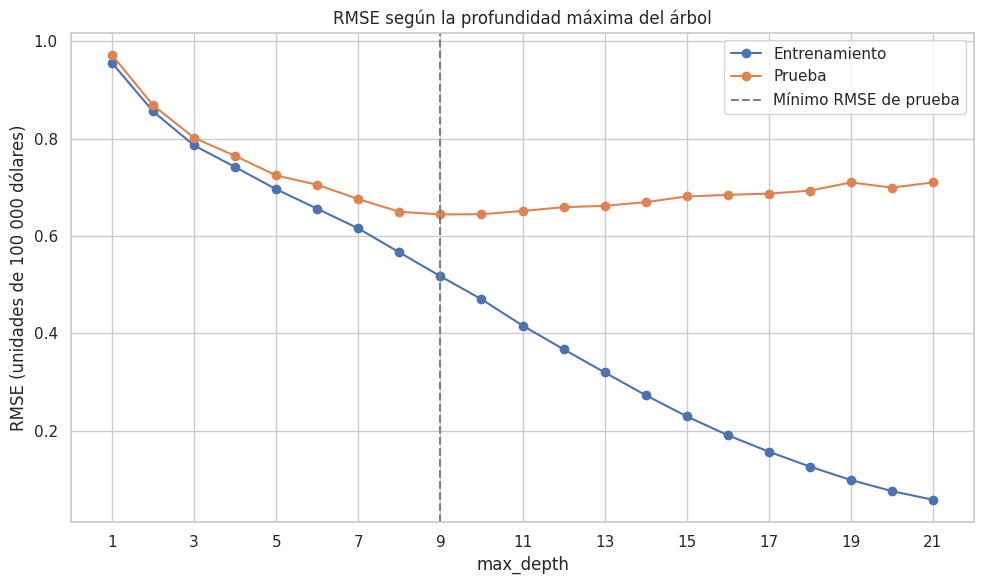

In [7]:
resultados_profundidad = []  # lista donde se guardan las métricas de cada profundidad
for profundidad in range(1, 22):  # recorre las profundidades 1, 2, ..., 21
    modelo = DecisionTreeRegressor(max_depth=profundidad, random_state=RANDOM_STATE)  # árbol con la profundidad actual
    modelo.fit(X_train, y_train)  # entrena el árbol
    rmse_tr, rmse_te, r2_tr, r2_te = evaluar(modelo, X_train, y_train, X_test, y_test)  # calcula las métricas
    resultados_profundidad.append({  # guarda una fila de resultados
        "max_depth": profundidad,  # profundidad máxima permitida
        "RMSE_train": rmse_tr,  # RMSE en entrenamiento
        "RMSE_test": rmse_te,  # RMSE en prueba
        "R2_test": r2_te,  # R² en prueba
        "Hojas": modelo.get_n_leaves()  # número de hojas del árbol
    })  # fin del diccionario
df_profundidad = pd.DataFrame(resultados_profundidad)  # convierte la lista en un DataFrame
display(df_profundidad)  # muestra la tabla completa
mejor_profundidad = df_profundidad.loc[df_profundidad["RMSE_test"].idxmin()]  # fila con el menor RMSE de prueba
print("Mejor max_depth:", int(mejor_profundidad["max_depth"]))  # profundidad con mejor generalización
print("RMSE de prueba en ese punto:", round(mejor_profundidad["RMSE_test"], 4))  # RMSE mínimo de prueba
plt.figure(figsize=(10, 6))  # crea la figura de comparación
plt.plot(df_profundidad["max_depth"], df_profundidad["RMSE_train"], marker="o", label="Entrenamiento")  # curva de entrenamiento
plt.plot(df_profundidad["max_depth"], df_profundidad["RMSE_test"], marker="o", label="Prueba")  # curva de prueba
plt.axvline(int(mejor_profundidad["max_depth"]), linestyle="--", color="gray", label="Mínimo RMSE de prueba")  # línea vertical en el óptimo
plt.title("RMSE según la profundidad máxima del árbol")  # título de la gráfica
plt.xlabel("max_depth")  # etiqueta del eje X
plt.ylabel("RMSE (unidades de 100 000 dólares)")  # etiqueta del eje Y
plt.xticks(range(1, 22, 2))  # marca las profundidades impares en el eje X
plt.legend()  # muestra la leyenda
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la gráfica

**Valores reales del análisis de profundidad** (se calculan al ejecutar).

In [8]:
p_opt = int(mejor_profundidad["max_depth"])  # profundidad óptima según RMSE de prueba
fila_21 = df_profundidad[df_profundidad["max_depth"] == 21].iloc[0]  # resultados con la mayor profundidad evaluada
fila_1 = df_profundidad[df_profundidad["max_depth"] == 1].iloc[0]  # resultados con la menor profundidad evaluada
print(f"Profundidad 1  -> RMSE train {fila_1['RMSE_train']:.4f} | RMSE test {fila_1['RMSE_test']:.4f}  (subajuste: ambos errores altos)")  # extremo simple
print(f"Profundidad {p_opt} -> RMSE train {df_profundidad.loc[p_opt-1,'RMSE_train']:.4f} | RMSE test {mejor_profundidad['RMSE_test']:.4f}  (mejor generalización)")  # punto óptimo
print(f"Profundidad 21 -> RMSE train {fila_21['RMSE_train']:.4f} | RMSE test {fila_21['RMSE_test']:.4f}  (sobreajuste: brecha grande)")  # extremo complejo

Profundidad 1  -> RMSE train 0.9555 | RMSE test 0.9717  (subajuste: ambos errores altos)
Profundidad 9 -> RMSE train 0.5172 | RMSE test 0.6443  (mejor generalización)
Profundidad 21 -> RMSE train 0.0579 | RMSE test 0.7100  (sobreajuste: brecha grande)


**Tu respuesta (4.2).** Al aumentar `max_depth`, el árbol hace más divisiones y puede describir patrones más finos, por lo que el **RMSE de entrenamiento disminuye de forma monótona**. El **RMSE de prueba**, en cambio, describe una curva en forma de "U": con profundidades bajas ambos errores son altos (**subajuste / sesgo alto**); al subir la profundidad el error de prueba mejora hasta un mínimo; después se estanca o empeora mientras el de entrenamiento sigue bajando (**sobreajuste / varianza alta**). El punto donde el modelo generaliza mejor es el de menor RMSE de prueba (marcado con la línea punteada), es decir, el mejor equilibrio sesgo–varianza.

**4.3 (validación de la selección).** Elegir la profundidad con el propio conjunto de prueba es optimista, porque el conjunto de prueba influye en la decisión. Como verificación, se repite la selección con validación cruzada de 5 folds **solo sobre el conjunto de entrenamiento**.

In [9]:
rmse_cv = []  # lista con el RMSE medio de validación cruzada por profundidad
for profundidad in range(1, 22):  # recorre las mismas profundidades
    modelo = DecisionTreeRegressor(max_depth=profundidad, random_state=RANDOM_STATE)  # árbol con la profundidad actual
    mse_folds = -cross_val_score(modelo, X_train, y_train, cv=5, scoring="neg_mean_squared_error")  # MSE en cada fold (sklearn lo devuelve negativo)
    rmse_cv.append(np.sqrt(mse_folds).mean())  # promedio del RMSE de los 5 folds
profundidad_cv = int(np.argmin(rmse_cv)) + 1  # profundidad con menor RMSE de validación cruzada (índice 0 = profundidad 1)
print("Mejor max_depth según validación cruzada (solo train):", profundidad_cv)  # imprime la profundidad elegida por CV
print("Mejor max_depth según el conjunto de prueba:", p_opt)  # imprime la elegida con el conjunto de prueba

Mejor max_depth según validación cruzada (solo train): 9
Mejor max_depth según el conjunto de prueba: 9


**Tu respuesta (4.4).** Si ambas profundidades coinciden o son cercanas, la selección es robusta; si difieren, es preferible reportar la elegida por validación cruzada, porque no utilizó el conjunto de prueba para decidir.

---
## Actividad 5 — Poda por complejidad de costo (`ccp_alpha`)

**5.1.** Aplica *cost-complexity pruning*, evalúa distintos valores de `ccp_alpha` con `ccp_alphas = ccp_alphas[::5]` y analiza su efecto en el error.

> El método `cost_complexity_pruning_path` pertenece al **modelo** (`DecisionTreeRegressor`), no es una función suelta de `sklearn.tree`. Se calcula solo con los datos de entrenamiento.

Total de alphas candidatos: 14833
Alphas a evaluar (ccp_alphas[::5]): 2967


,ccp_alpha,RMSE_train,RMSE_test,R2_test,Profundidad,Hojas
0,0.0000e+00,3.2183e-16,0.7037,0.6221,34,15854
197,1.9380e-09,8.2790e-04,0.7037,0.6221,32,14853
394,9.8110e-09,2.4472e-03,0.7037,0.6221,32,13865
591,2.7636e-08,4.8493e-03,0.7038,0.6220,31,12877
788,6.6891e-08,8.2511e-03,0.7038,0.6220,31,11891
985,1.3593e-07,1.2834e-02,0.7037,0.6221,30,10895
1182,2.7148e-07,1.9001e-02,0.7038,0.6220,30,9902
1379,5.1099e-07,2.7173e-02,0.7037,0.6221,30,8899
1576,9.5216e-07,3.8286e-02,0.7026,0.6233,29,7878
1773,1.7033e-06,5.2756e-02,0.7025,0.6233,28,6863


Mejor ccp_alpha: 0.0003689303672913904
RMSE de prueba con poda: 0.6264
Profundidad / hojas del árbol podado óptimo: 16 / 271


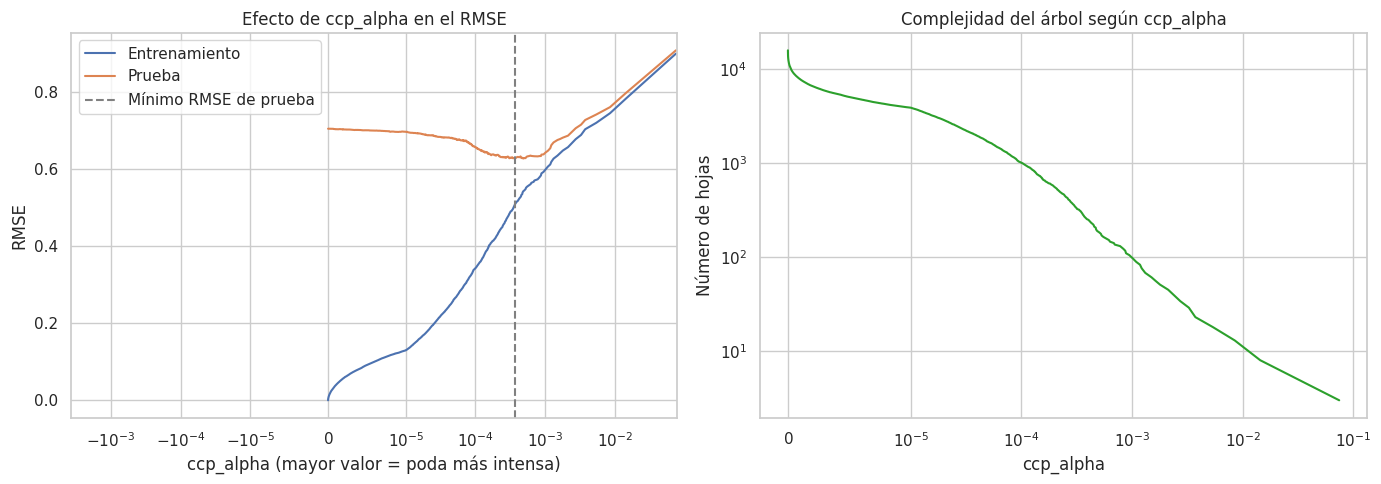

In [10]:
arbol_ruta = DecisionTreeRegressor(random_state=RANDOM_STATE)  # árbol completo sobre el que se calcula la ruta de poda
ruta_poda = arbol_ruta.cost_complexity_pruning_path(X_train, y_train)  # calcula los alphas candidatos usando solo entrenamiento
ccp_alphas = ruta_poda.ccp_alphas  # arreglo con los valores candidatos de ccp_alpha (de menor a mayor)
print("Total de alphas candidatos:", len(ccp_alphas))  # cantidad de candidatos antes de muestrear
ccp_alphas = ccp_alphas[::5]  # toma uno de cada cinco, como pide la actividad
print("Alphas a evaluar (ccp_alphas[::5]):", len(ccp_alphas))  # cantidad de candidatos que se evaluarán
resultados_poda = []  # lista donde se guardan las métricas por alpha
for alpha in ccp_alphas:  # recorre cada alpha seleccionado
    modelo_podado = DecisionTreeRegressor(random_state=RANDOM_STATE, ccp_alpha=max(float(alpha), 0.0))  # árbol podado (alpha no negativo)
    modelo_podado.fit(X_train, y_train)  # entrena el árbol podado
    rmse_tr, rmse_te, r2_tr, r2_te = evaluar(modelo_podado, X_train, y_train, X_test, y_test)  # calcula las métricas
    resultados_poda.append({  # guarda una fila de resultados
        "ccp_alpha": float(alpha),  # valor de alpha usado
        "RMSE_train": rmse_tr,  # RMSE en entrenamiento
        "RMSE_test": rmse_te,  # RMSE en prueba
        "R2_test": r2_te,  # R² en prueba
        "Profundidad": modelo_podado.get_depth(),  # profundidad resultante tras la poda
        "Hojas": modelo_podado.get_n_leaves()  # número de hojas resultante tras la poda
    })  # fin del diccionario
df_poda = pd.DataFrame(resultados_poda)  # convierte los resultados en una tabla
display(df_poda.iloc[::max(1, len(df_poda) // 15)])  # muestra una muestra de ~15 filas para no saturar la pantalla
mejor_poda = df_poda.loc[df_poda["RMSE_test"].idxmin()]  # fila con el menor RMSE de prueba
print("Mejor ccp_alpha:", mejor_poda["ccp_alpha"])  # alpha con mejor generalización
print("RMSE de prueba con poda:", round(mejor_poda["RMSE_test"], 4))  # RMSE mínimo de prueba con poda
print("Profundidad / hojas del árbol podado óptimo:", int(mejor_poda["Profundidad"]), "/", int(mejor_poda["Hojas"]))  # complejidad del árbol óptimo
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))  # figura con dos paneles lado a lado
ejes[0].plot(df_poda["ccp_alpha"], df_poda["RMSE_train"], label="Entrenamiento")  # RMSE de entrenamiento vs alpha
ejes[0].plot(df_poda["ccp_alpha"], df_poda["RMSE_test"], label="Prueba")  # RMSE de prueba vs alpha
ejes[0].axvline(mejor_poda["ccp_alpha"], linestyle="--", color="gray", label="Mínimo RMSE de prueba")  # marca el mejor alpha
ejes[0].set_xscale("symlog", linthresh=1e-5)  # escala log simétrica (admite alpha = 0)
ejes[0].set_title("Efecto de ccp_alpha en el RMSE")  # título del primer panel
ejes[0].set_xlabel("ccp_alpha (mayor valor = poda más intensa)")  # etiqueta del eje X
ejes[0].set_ylabel("RMSE")  # etiqueta del eje Y
ejes[0].legend()  # leyenda del primer panel
ejes[1].plot(df_poda["ccp_alpha"], df_poda["Hojas"], color="tab:green")  # número de hojas vs alpha
ejes[1].set_xscale("symlog", linthresh=1e-5)  # misma escala en el eje X
ejes[1].set_yscale("log")  # escala logarítmica en Y porque el número de hojas varía en órdenes de magnitud
ejes[1].set_title("Complejidad del árbol según ccp_alpha")  # título del segundo panel
ejes[1].set_xlabel("ccp_alpha")  # etiqueta del eje X
ejes[1].set_ylabel("Número de hojas")  # etiqueta del eje Y
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la figura

**Tu respuesta (5.2).** `ccp_alpha` penaliza el número de hojas: con `alpha = 0` el árbol queda completo (sobreajustado) y, al aumentarlo, se podan las ramas que aportan poca reducción de error por hoja, de modo que **disminuyen hojas y profundidad** (segundo panel). El RMSE de entrenamiento sube de forma sostenida porque el árbol se simplifica; el de prueba suele **mejorar con una poda moderada** (se reduce la varianza) y **empeorar con una poda excesiva** (se pierde información útil y aparece subajuste, hasta llegar a un árbol de una sola hoja). El mejor alpha encontrado es el mejor de los valores muestreados con `ccp_alphas[::5]`, no necesariamente el óptimo entre todos los posibles.

---
## Actividad 6 — Comparación de configuraciones y variables relevantes

**6.1.** Compara el modelo base, el mejor `max_depth` y el mejor `ccp_alpha`, y selecciona la configuración con mejor desempeño en prueba.

In [11]:
configuraciones = {  # diccionario con los hiperparámetros de las tres configuraciones
    "Base (sin restricción)": {"max_depth": None, "ccp_alpha": 0.0},  # árbol completo
    f"Mejor max_depth ({p_opt})": {"max_depth": p_opt, "ccp_alpha": 0.0},  # mejor profundidad
    f"Mejor ccp_alpha ({mejor_poda['ccp_alpha']:.2e})": {"max_depth": None, "ccp_alpha": float(mejor_poda["ccp_alpha"])}  # mejor poda
}  # fin del diccionario
filas = []  # lista de filas para la tabla comparativa
modelos_finales = {}  # diccionario para conservar cada modelo entrenado
for nombre, params in configuraciones.items():  # recorre cada configuración
    m = DecisionTreeRegressor(random_state=RANDOM_STATE, **params)  # crea el modelo con sus hiperparámetros
    m.fit(X_train, y_train)  # entrena el modelo
    rmse_tr, rmse_te, r2_tr, r2_te = evaluar(m, X_train, y_train, X_test, y_test)  # calcula las métricas
    modelos_finales[nombre] = m  # guarda el modelo entrenado
    filas.append({"Configuración": nombre, "RMSE_train": rmse_tr, "RMSE_test": rmse_te, "R2_train": r2_tr, "R2_test": r2_te, "Profundidad": m.get_depth(), "Hojas": m.get_n_leaves()})  # agrega la fila
comparacion = pd.DataFrame(filas)  # convierte las filas en tabla
display(comparacion)  # muestra la tabla comparativa
nombre_mejor = comparacion.loc[comparacion["RMSE_test"].idxmin(), "Configuración"]  # configuración con menor RMSE de prueba
mejor_modelo = modelos_finales[nombre_mejor]  # modelo asociado a esa configuración
print("Configuración con mejor desempeño en prueba:", nombre_mejor)  # imprime la ganadora

,Configuración,RMSE_train,RMSE_test,R2_train,R2_test,Profundidad,Hojas
0,Base (sin restricción),3.2183e-16,0.7037,1.0000,0.6221,34,15854
1,Mejor max_depth (9),5.1716e-01,0.6443,0.7999,0.6833,9,450
2,Mejor ccp_alpha (3.69e-04),5.0820e-01,0.6264,0.8068,0.7006,16,271


Configuración con mejor desempeño en prueba: Mejor ccp_alpha (3.69e-04)


**6.2.** Variables más relevantes según el mejor modelo (importancia basada en la reducción de impureza).

,Variable,Importancia
0,MedInc,0.6287
5,AveOccup,0.1287
6,Latitude,0.0764
7,Longitude,0.0638
1,HouseAge,0.0435
2,AveRooms,0.0370
4,Population,0.0123
3,AveBedrms,0.0095


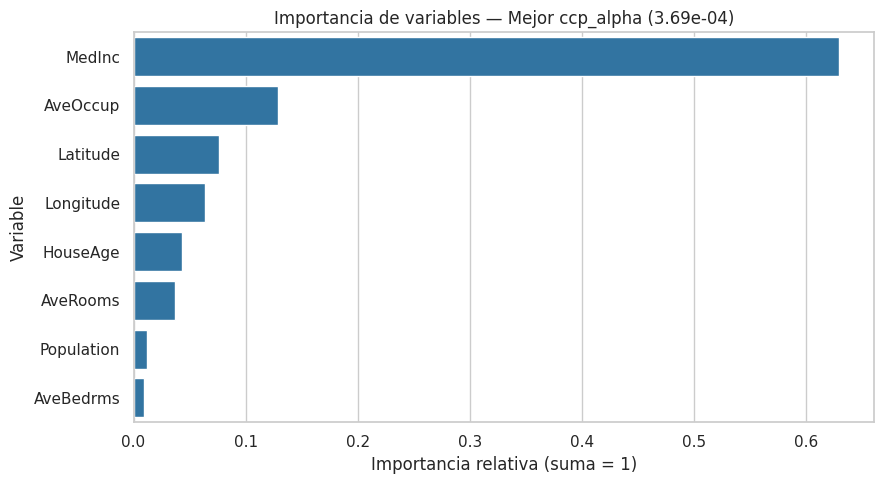

Tres variables principales: ['MedInc', 'AveOccup', 'Latitude']
Importancia acumulada de las tres: 83.4%


In [12]:
importancias = pd.DataFrame({"Variable": X.columns, "Importancia": mejor_modelo.feature_importances_})  # tabla variable-importancia
importancias = importancias.sort_values("Importancia", ascending=False)  # ordena de mayor a menor importancia
display(importancias)  # muestra la tabla de importancias
plt.figure(figsize=(9, 5))  # crea la figura del gráfico de barras
sns.barplot(data=importancias, x="Importancia", y="Variable", color="tab:blue")  # barras horizontales de importancia
plt.title(f"Importancia de variables — {nombre_mejor}")  # título con el nombre del modelo
plt.xlabel("Importancia relativa (suma = 1)")  # etiqueta del eje X
plt.ylabel("Variable")  # etiqueta del eje Y
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la gráfica
top3 = importancias.head(3)  # las tres variables más importantes
print("Tres variables principales:", top3["Variable"].tolist())  # imprime sus nombres
print(f"Importancia acumulada de las tres: {top3['Importancia'].sum():.1%}")  # porcentaje de importancia que concentran

---
## Interpretación de resultados (respuestas justificadas)

Las cifras exactas de cada respuesta se imprimen en la celda **valores reales** que aparece al final de esta sección.

**1. ¿El modelo base presenta sobreajuste? Explique.**
Sí, cuando el RMSE de entrenamiento es muy inferior al de prueba y el R² de entrenamiento supera claramente al de prueba. Un árbol con `max_depth=None` crece hasta aislar casi cada observación, por lo que memoriza el ruido del entrenamiento (sesgo bajo, varianza alta) y generaliza peor.

**2. ¿Cómo afecta la profundidad del árbol al error?**
El error de entrenamiento baja siempre al aumentar la profundidad. El error de prueba baja al principio (se reduce el subajuste) y luego se estanca o sube (aparece el sobreajuste). Existe una profundidad intermedia donde el equilibrio sesgo–varianza es mejor.

**3. ¿Qué efecto tiene la poda en el modelo?**
La poda por complejidad de costo reduce hojas y profundidad. Una poda moderada disminuye la varianza y mejora (o mantiene) el error de prueba con un árbol mucho más simple; una poda excesiva elimina patrones útiles y provoca subajuste.

**4. ¿Cuál configuración produce el mejor desempeño?**
La que obtiene menor RMSE (y mayor R²) en prueba entre las tres comparadas; ante desempeños similares conviene preferir el árbol más simple. Como la selección usó el conjunto de prueba, el resultado es ligeramente optimista; la validación cruzada de la Actividad 4.3 es el control de esa limitación.

**5. ¿Qué variables son más relevantes según el modelo?**
Las primeras de la tabla de importancias. En California Housing suelen dominar el ingreso mediano del distrito (`MedInc`) y variables de ubicación/ocupación, pero lo que cuenta es lo que arroje la ejecución. La importancia mide la contribución a la reducción de impureza de *ese* árbol; no implica causalidad y puede repartirse entre variables correlacionadas (por ejemplo, `Latitude` y `Longitude`).

In [13]:
print("=== VALORES REALES QUE RESPALDAN LAS RESPUESTAS ===")  # encabezado del resumen
print(f"1) Modelo base: RMSE train {rmse_tr_b:.4f} vs test {rmse_te_b:.4f}; R² train {r2_tr_b:.4f} vs test {r2_te_b:.4f} -> " + ("hay sobreajuste." if (r2_tr_b - r2_te_b) > 0.10 else "sin sobreajuste claro."))  # respuesta 1 con cifras
print(f"2) Profundidad óptima: {p_opt} (RMSE prueba {mejor_profundidad['RMSE_test']:.4f}); con 21 niveles el RMSE de prueba es {fila_21['RMSE_test']:.4f} y el de entrenamiento {fila_21['RMSE_train']:.4f}.")  # respuesta 2 con cifras
print(f"3) Poda: mejor ccp_alpha {mejor_poda['ccp_alpha']:.2e} con {int(mejor_poda['Hojas'])} hojas (el modelo base tiene {modelo_base.get_n_leaves()}); RMSE prueba {mejor_poda['RMSE_test']:.4f}.")  # respuesta 3 con cifras
print(f"4) Mejor configuración: {nombre_mejor} con RMSE de prueba {comparacion['RMSE_test'].min():.4f} y R² de prueba {comparacion.loc[comparacion['RMSE_test'].idxmin(), 'R2_test']:.4f}.")  # respuesta 4 con cifras
print(f"5) Variables principales: {top3['Variable'].tolist()} (concentran {top3['Importancia'].sum():.1%} de la importancia).")  # respuesta 5 con cifras
print(f"   Profundidad elegida por validación cruzada: {profundidad_cv} (vs {p_opt} elegida con prueba).")  # control de la selección

=== VALORES REALES QUE RESPALDAN LAS RESPUESTAS ===
1) Modelo base: RMSE train 0.0000 vs test 0.7037; R² train 1.0000 vs test 0.6221 -> hay sobreajuste.
2) Profundidad óptima: 9 (RMSE prueba 0.6443); con 21 niveles el RMSE de prueba es 0.7100 y el de entrenamiento 0.0579.
3) Poda: mejor ccp_alpha 3.69e-04 con 271 hojas (el modelo base tiene 15854); RMSE prueba 0.6264.
4) Mejor configuración: Mejor ccp_alpha (3.69e-04) con RMSE de prueba 0.6264 y R² de prueba 0.7006.
5) Variables principales: ['MedInc', 'AveOccup', 'Latitude'] (concentran 83.4% de la importancia).
   Profundidad elegida por validación cruzada: 9 (vs 9 elegida con prueba).


### Conclusión

La profundidad y la poda son dos formas de controlar la complejidad del árbol. Un árbol demasiado simple subajusta (sesgo alto) y uno demasiado profundo sobreajusta (varianza alta); el mejor modelo es el que equilibra ambos efectos y obtiene el menor error en datos no vistos. Aunque un árbol individual es muy interpretable, su desempeño es inestable frente a cambios en los datos; por eso, en la práctica, suele mejorarse con métodos de conjunto (bosques aleatorios, *boosting*), y la selección de hiperparámetros debe hacerse con validación cruzada reservando la prueba para la evaluación final.

---
## Fuentes bibliográficas

1. Pace, R. K., & Barry, R. (1997). Sparse spatial autoregressions. *Statistics & Probability Letters, 33*(3), 291–297. https://doi.org/10.1016/S0167-7152(96)00140-X (origen del dataset California Housing)
2. Scikit-learn developers. (s. f.). *fetch_california_housing*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html
3. Scikit-learn developers. (s. f.). *DecisionTreeRegressor*. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html
4. Scikit-learn developers. (s. f.). *Post pruning decision trees with cost complexity pruning*. https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html
5. Scikit-learn developers. (s. f.). *Mean squared error regression loss*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html
6. Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and regression trees*. Chapman & Hall/CRC.
7. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2.ª ed.). Springer.